A decision tree is a supervised machine learning algorithm that breaks down a dataset into smaller subsets while building an upside-down, flowchart-like tree structure. It mimics human decision-making by using conditional "if-then-else" logic to predict discrete categories or continuous numerical values.

Gini Impurity / Index: Measures the probability of a random data point being misclassified. It is fast to compute; a Gini score of 0 means a node is perfectly pure.

Entropy: Measures the randomness or disorder within a node.

Information Gain: Calculates the drop in entropy after a split. The algorithm naturally picks the feature with the highest information gain.

Advantages

Easy to understand

Easy to visualize

Handles numerical and categorical data

Requires little preprocessing

Fast prediction

Disadvantages

Can overfit

Sensitive to noisy data

Small changes may produce a different tree

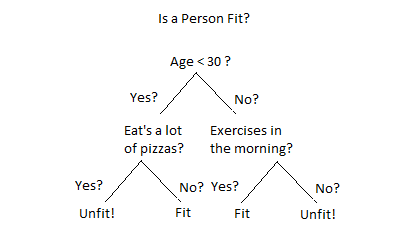

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Teen_Mental_Health_Dataset.csv")

In [ ]:
features = [
    "daily_social_media_hours",
    "sleep_hours",
    "academic_performance",
    "stress_level",
    "anxiety_level",
    "addiction_level"
]

X = df[features]
y = df["depression_label"]

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
dt_prediction = dt_model.predict(X_test)

In [ ]:
print("Decision Tree Accuracy")
print(accuracy_score(y_test, dt_prediction))

Decision Tree Accuracy
1.0


In [ ]:
print(classification_report(y_test, dt_prediction))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       234
           1       1.00      1.00      1.00         6

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



In [ ]:
print(confusion_matrix(y_test, dt_prediction))

[[234   0]
 [  0   6]]


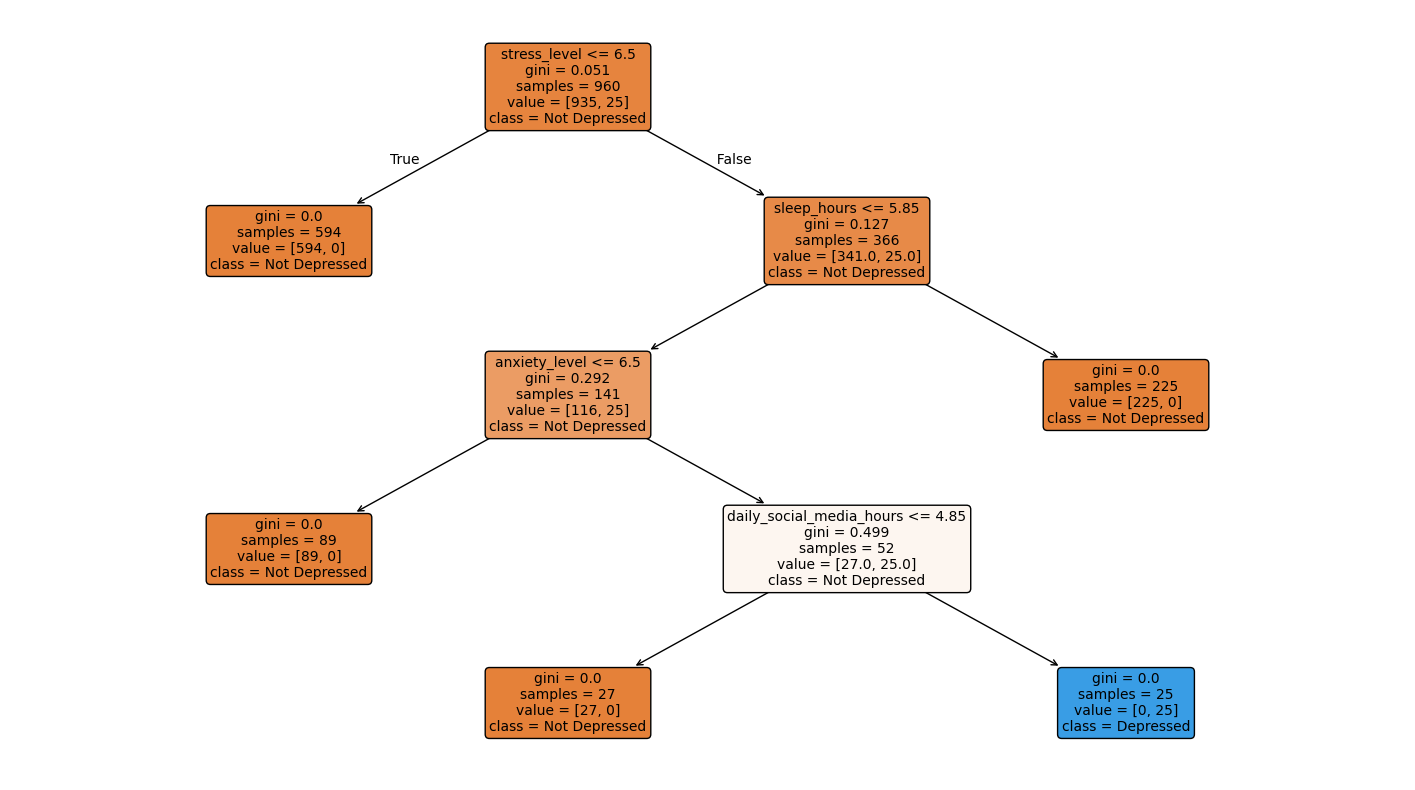

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18,10))

plot_tree(
    dt_model,
    feature_names=features,
    class_names=["Not Depressed","Depressed"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

In [ ]:
new_student = [[7,5,60,8,7,6]]

prediction = dt_model.predict(new_student)

if prediction[0] == 1:
    print("Depressed")
else:
    print("Not Depressed")

Depressed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [ ]:
new_student = [[3,8,6,8,7,6]]

prediction = dt_model.predict(new_student)

if prediction[0] == 1:
    print("Depressed")
else:
    print("Not Depressed")

Not Depressed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


Random Forest is a powerful supervised machine learning algorithm that builds an ensemble (collection) of multiple decision trees to make more accurate and stable predictions. It relies on the "wisdom of the crowd" principle: combining the results of many individual trees always yields a more reliable outcome than relying on a single tree alone

Advantages

High accuracy

Reduces overfitting

Handles missing values reasonably well

Works well on large datasets

Robust to noise

Disadvantages

Slower than a single Decision Tree

Uses more memory

Harder to interpret

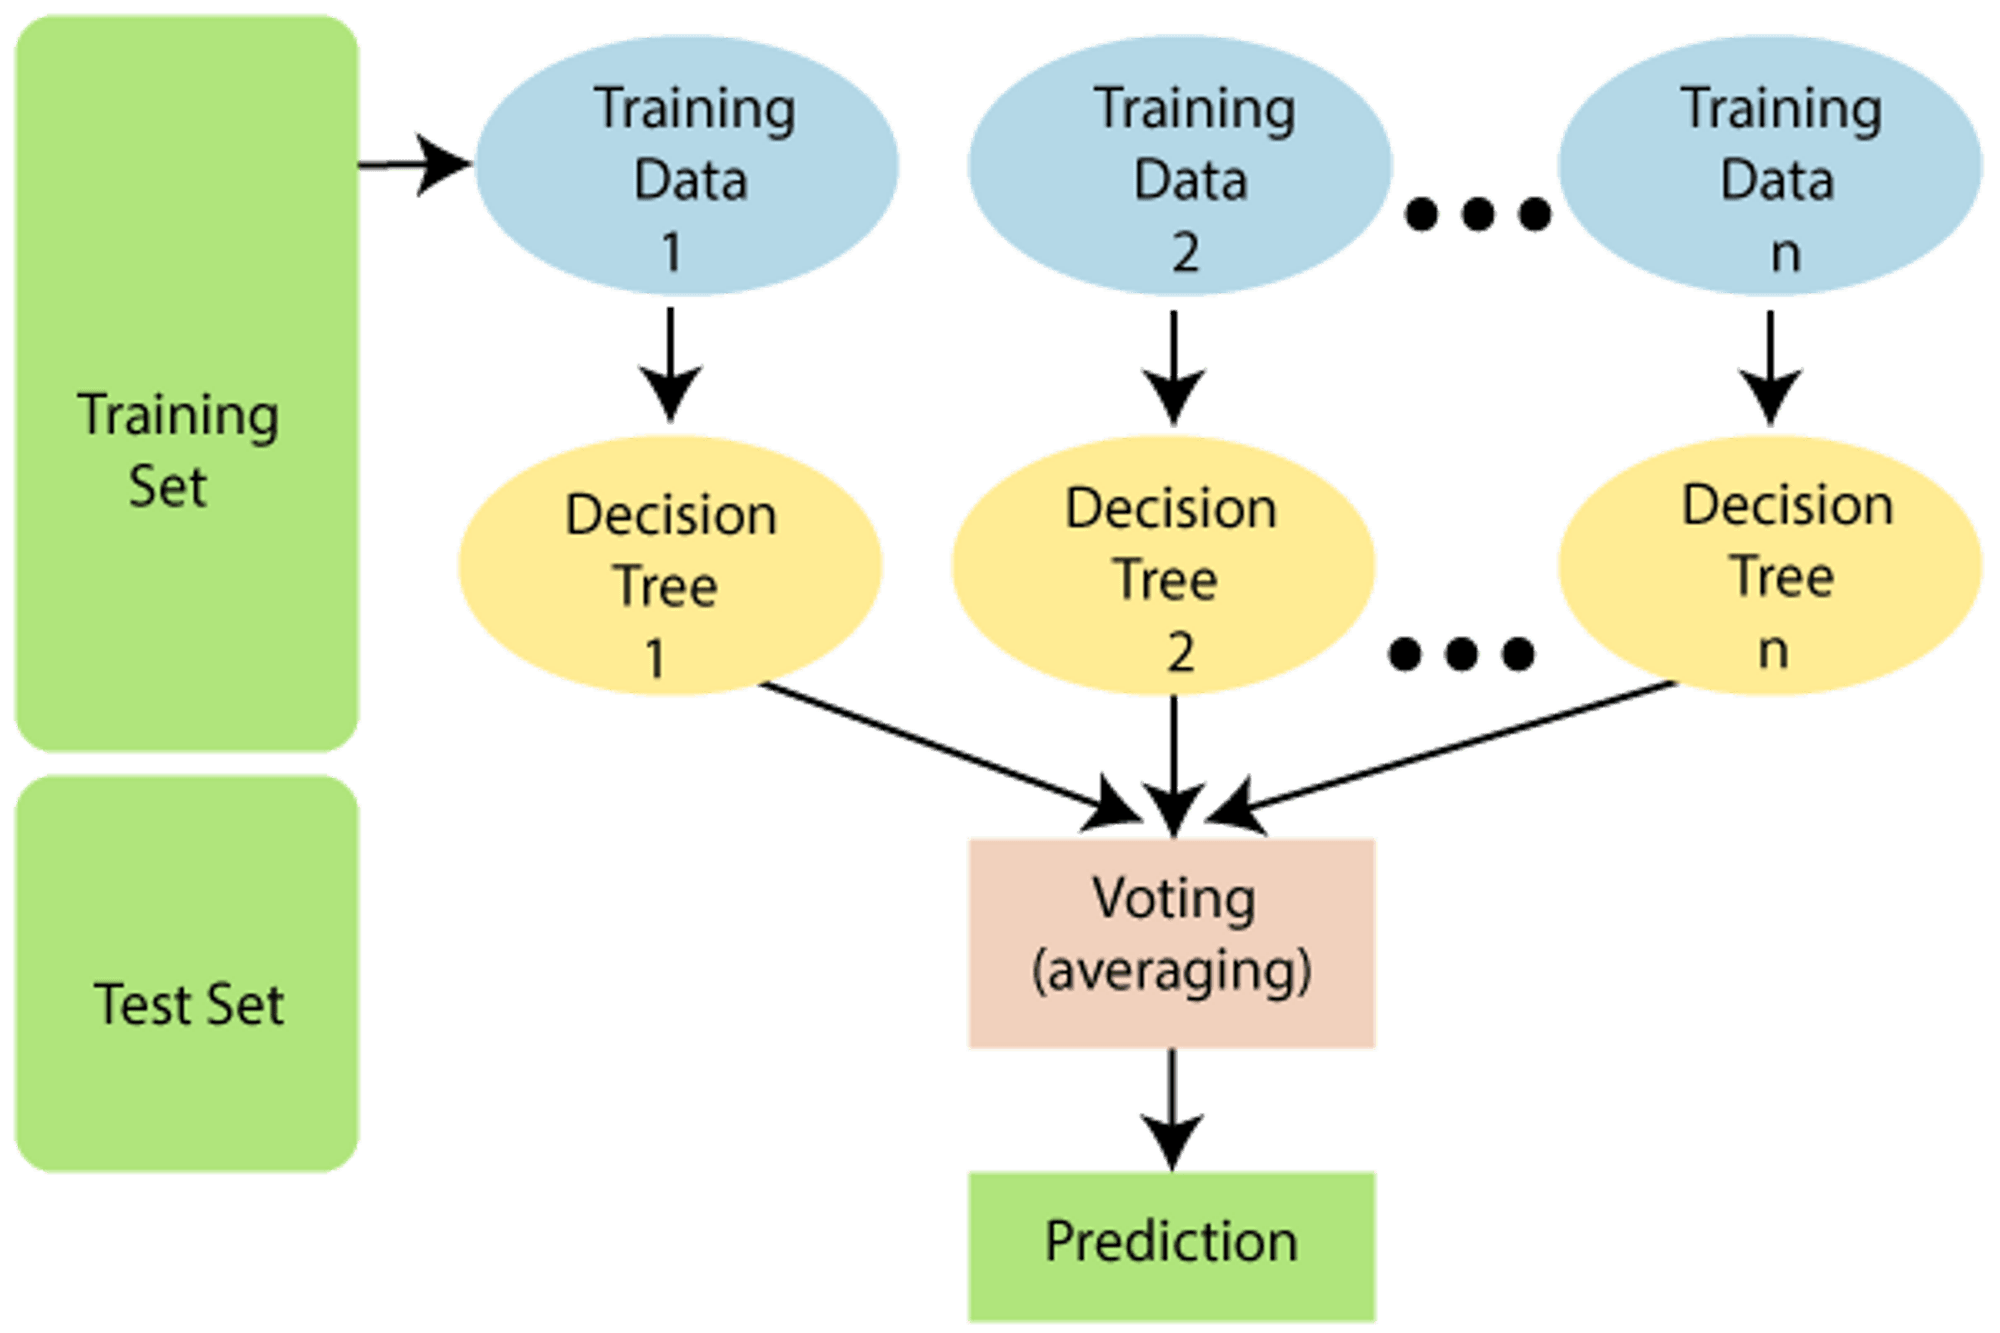

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

In [ ]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, random_state=42)

In [ ]:
rf_prediction = rf_model.predict(X_test)

In [ ]:
print("Random Forest Accuracy")
print(accuracy_score(y_test, rf_prediction))

Random Forest Accuracy
0.9791666666666666


In [ ]:
print(classification_report(y_test, rf_prediction))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       234
           1       1.00      0.17      0.29         6

    accuracy                           0.98       240
   macro avg       0.99      0.58      0.64       240
weighted avg       0.98      0.98      0.97       240



In [ ]:
print(confusion_matrix(y_test, rf_prediction))

[[234   0]
 [  5   1]]


In [ ]:
new_student = [[7,5,60,8,7,6]]

prediction = rf_model.predict(new_student)

if prediction[0] == 1:
    print("Depressed")
else:
    print("Not Depressed")

Not Depressed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
new_student = [[9,8,2.4,9,9,9]]
prediction = rf_model.predict(new_student)

if prediction[0] == 1:
    print("Depressed")
else:
    print("Not Depressed")

Not Depressed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                    Feature  Importance
1               sleep_hours    0.277683
0  daily_social_media_hours    0.246302
4             anxiety_level    0.174134
3              stress_level    0.173261
2      academic_performance    0.072960
5           addiction_level    0.055660


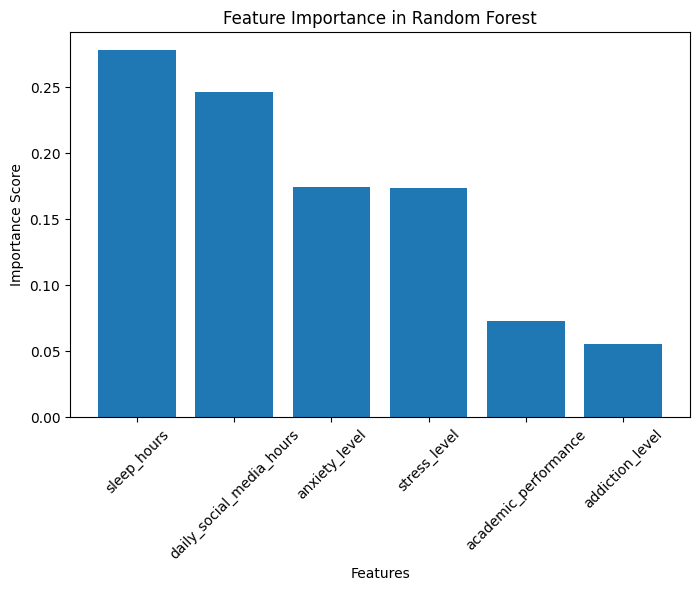

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xticks(rotation=45)
plt.title("Feature Importance in Random Forest")
plt.xlabel("Features")
plt.ylabel("Importance Score")

plt.show()

| Feature          | Decision Tree           | Random Forest               |
| ---------------- | ----------------------- | --------------------------- |
| Number of Trees  | One                     | Many (e.g., 100)            |
| Prediction       | Single tree             | Majority vote of many trees |
| Accuracy         | Good                    | Usually higher              |
| Overfitting      | High risk               | Much lower                  |
| Training Speed   | Faster                  | Slower                      |
| Prediction Speed | Fast                    | Slightly slower             |
| Interpretability | Very easy               | More difficult              |
| Best Use         | Understanding decisions | High-performance prediction |
